In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
# Change this path if the four processed CSV files are stored elsewhere.
DATA_DIR = Path("../data")

required_files = ["X_train.csv", "X_test.csv", "y_train.csv", "y_test.csv"]
missing = [name for name in required_files if not (DATA_DIR / name).exists()]

if missing:
    raise FileNotFoundError(
        f"Could not find {missing} in {DATA_DIR.resolve()}. "
        "Run the feature-engineering notebook first, or update DATA_DIR."
    )

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train_df = pd.read_csv(DATA_DIR / "y_train.csv")
y_test_df = pd.read_csv(DATA_DIR / "y_test.csv")

# Remove any index columns accidentally saved to the CSV files.
def remove_saved_index(df):
    return df.loc[:, ~df.columns.astype(str).str.match(r"^Unnamed:")]

X_train = remove_saved_index(X_train)
X_test = remove_saved_index(X_test)
y_train_df = remove_saved_index(y_train_df)
y_test_df = remove_saved_index(y_test_df)

# Extract the target column from the target CSVs.
def extract_target(target_df):
    if "Target" in target_df.columns:
        return target_df["Target"]
    if target_df.shape[1] == 1:
        return target_df.iloc[:, 0]
    raise ValueError(
        "Could not identify the target column in the y CSV. "
        f"Available columns: {target_df.columns.tolist()}"
    )

y_train = extract_target(y_train_df)
y_test = extract_target(y_test_df)

# Ensure training and test data have exactly the same columns and order.
if set(X_train.columns) != set(X_test.columns):
    raise ValueError("Training and test feature columns do not match.")

X_test = X_test[X_train.columns]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nNumber of input features:", X_train.shape[1])
if X_train.shape[1] != 232:
    raise ValueError(
        f"Expected 232 processed features, but found {X_train.shape[1]}. "
        "Check that you loaded the feature-engineering notebook's output files."
    )

Training features: (3539, 232)
Testing features: (885, 232)
Training target: (3539,)
Testing target: (885,)

Number of input features: 232


First 30 predictions:


,Actual,Predicted,Correct
0,Graduate,Graduate,True
1,Graduate,Graduate,True
2,Enrolled,Enrolled,True
3,Graduate,Graduate,True
4,Graduate,Graduate,True
5,Graduate,Enrolled,False
6,Graduate,Graduate,True
7,Graduate,Graduate,True
8,Graduate,Graduate,True
9,Graduate,Graduate,True



Accuracy: 0.6802

Classification report:
              precision    recall  f1-score   support

     Dropout       0.75      0.64      0.69       284
    Enrolled       0.36      0.26      0.30       159
    Graduate       0.72      0.86      0.78       442

    accuracy                           0.68       885
   macro avg       0.61      0.59      0.59       885
weighted avg       0.66      0.68      0.67       885

Macro precision: 0.6078
Macro recall: 0.5858
Macro F1: 0.591


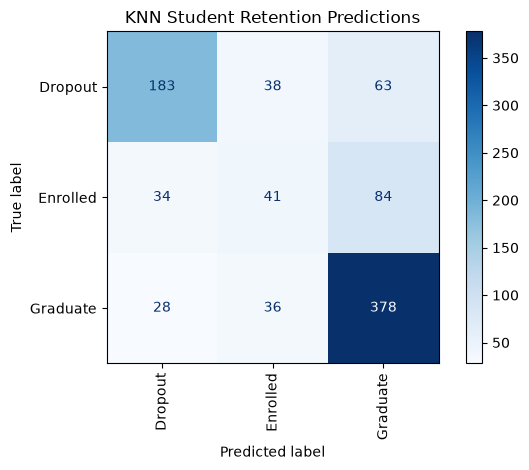

In [3]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
predictions["Correct"] = predictions["Actual"] == predictions["Predicted"]

print("First 30 predictions:")
display(predictions.head(30))

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Macro precision:", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Macro recall:", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", xticks_rotation="vertical"
)
plt.title("KNN Student Retention Predictions")
plt.tight_layout()
plt.show()

Optimal K: 6
Best cross-validation macro F1: 0.6069

Optimised test accuracy: 0.6814

Optimised classification report:
              precision    recall  f1-score   support

     Dropout       0.76      0.67      0.71       284
    Enrolled       0.31      0.17      0.22       159
    Graduate       0.70      0.87      0.78       442

    accuracy                           0.68       885
   macro avg       0.59      0.57      0.57       885
weighted avg       0.65      0.68      0.66       885

Optimised macro precision: 0.5919
Optimised macro recall: 0.5711
Optimised macro F1: 0.5706


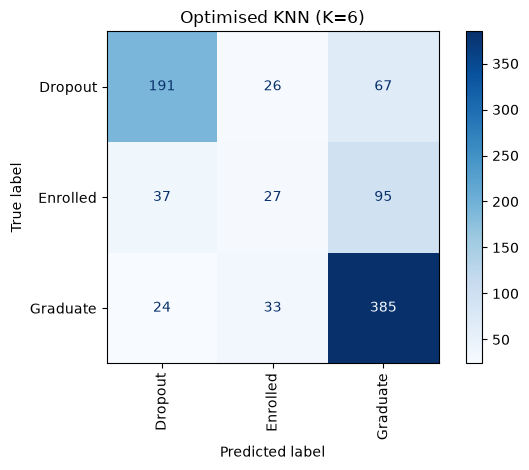

In [4]:
param_grid = {"n_neighbors": range(1, 31)}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Optimal K:", grid.best_params_["n_neighbors"])
print("Best cross-validation macro F1:", round(grid.best_score_, 4))

best_knn = grid.best_estimator_
y_pred_best = best_knn.predict(X_test)

print("\nOptimised test accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print("\nOptimised classification report:")
print(classification_report(y_test, y_pred_best, zero_division=0))

print("Optimised macro precision:", round(precision_score(y_test, y_pred_best, average="macro", zero_division=0), 4))
print("Optimised macro recall:", round(recall_score(y_test, y_pred_best, average="macro", zero_division=0), 4))
print("Optimised macro F1:", round(f1_score(y_test, y_pred_best, average="macro", zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, cmap="Blues", xticks_rotation="vertical"
)
plt.title(f"Optimised KNN (K={grid.best_params_['n_neighbors']})")
plt.tight_layout()
plt.show()

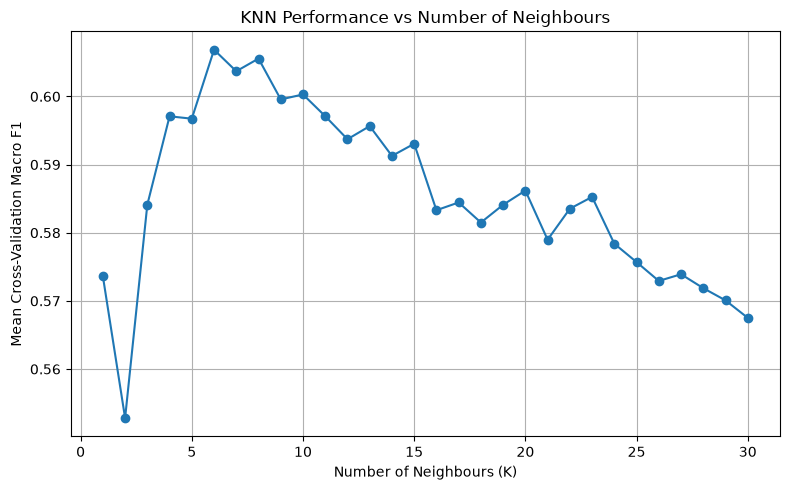

In [5]:
cv_results = pd.DataFrame(grid.cv_results_)

plt.figure(figsize=(8, 5))
plt.plot(
    param_grid["n_neighbors"],
    cv_results["mean_test_score"],
    marker="o"
)
plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Mean Cross-Validation Macro F1")
plt.title("KNN Performance vs Number of Neighbours")
plt.grid(True)
plt.tight_layout()
plt.show()